# 01 - Raw Data EDA (Omar, S1.12)

This notebook looks at the **raw** IBL data of the first session in `sessions.yaml`, exactly as IBL's own loaders return it, before any of our cleaning. It is the "before" picture: it shows the problems that the cleaning in `src/data/clean_trials.py` has to fix. No model is trained here.

## Plan

1. Pick the first session of `sessions.yaml` and connect to IBL.
2. Load its raw trials table with IBL's loader and describe every column.
3. Look at the choices and the contrasts.
4. Find the blocks of the block bias.
5. Look at the raw reaction times and the cleaning limits.
6. Load the good neurons of its probes and count them per brain region.
7. Draw a raster of 20 neurons around the first wheel movement.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "config.yaml").exists():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Open this notebook inside the brain-decoding repository.")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.common.settings import connect_ibl, load_config, load_session_info, load_session_list
from src.data.clean_trials import load_trials
from src.data.neurons import load_neurons
from src.analysis.eda import find_blocks, region_counts, trials_overview

config = load_config()
d = config["data"]
print("Release freeze:", config["ibl"]["release_freeze"])
print("Reaction-time limits (s):", d["min_reaction_time"], "to", d["max_reaction_time"])
print("Feature window (s):", d["window"])

Release freeze: 2023_12_bwm_release
Reaction-time limits (s): 0.08 to 2.0
Feature window (s): [-0.1, 0.0]


## 1. The session

In [2]:
session_id = load_session_list()[0]
info = load_session_info(session_id)
print("Session:", session_id)
print("Mouse:", info["subject"], "| Lab:", info["lab"], "| Probes:", len(info["pids"]))

one = connect_ibl()

Session: 746d1902-fa59-4cab-b0aa-013be36060d5
Mouse: ZFM-01592 | Lab: mainenlab | Probes: 2


## 2. The raw trials table

`load_trials` calls IBL's `load_trials_and_mask`. It returns the full trials table and IBL's own include/exclude mask. Nothing is removed yet.

In [3]:
trials, official_mask = load_trials(one, session_id, config)
print("Trials in the raw table:", len(trials))
print("Trials IBL's official mask keeps:", int(official_mask.sum()))
print("Trials IBL's official mask removes:", int((~official_mask).sum()))
display(trials_overview(trials))

D:\projects\brain-decoding\.venv\Lib\site-packages\one\webclient.py:1053: RuntimeWarning: The shared public account will be retired soon. Register your own account at https://openalyx.internationalbrainlab.org/signup
  emit(message)


Trials in the raw table: 660
Trials IBL's official mask keeps: 481
Trials IBL's official mask removes: 179


,column,type,n_missing,example
0,goCueTrigger_times,float64,0,39.619303
1,intervals_bpod_0,float64,0,0.000000
2,intervals_bpod_1,float64,0,15.847502
3,quiescencePeriod,float64,0,0.541949
4,stimOff_times,float64,0,45.769123
5,response_times,float64,0,44.675747
6,stimOn_times,float64,0,39.619104
7,contrastLeft,float64,347,0.250000
8,probabilityLeft,float64,0,0.500000
9,feedbackType,float64,0,1.000000


## 3. Choices and contrasts

`choice` is -1, +1, or 0 when the mouse did not answer. The picture is on one side only, so exactly one of `contrastLeft` / `contrastRight` is filled. The signed contrast is `contrastLeft`, or minus `contrastRight`; 0 means no picture.

Choices: {-1.0: 395, 0.0: 10, 1.0: 255}
Trials with both sides filled: 0
Trials with no side filled: 0


,trials,share_choice_plus1
signed_contrast,,
-1.0000,72,0.000
-0.2500,63,0.032
-0.1250,84,0.050
-0.0625,73,0.129
0.0000,87,0.356
0.0625,66,0.545
0.1250,74,0.689
0.2500,71,0.857
1.0000,70,0.886


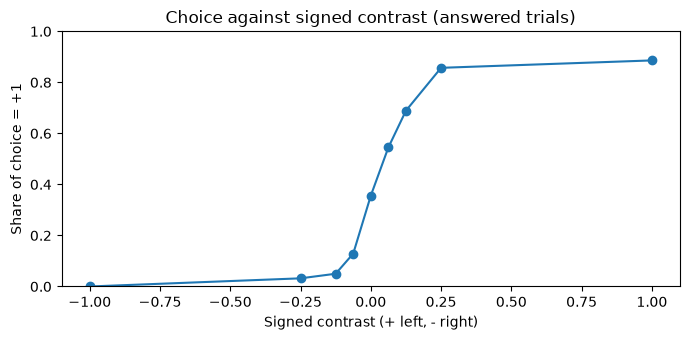

In [4]:
print("Choices:", trials["choice"].value_counts(dropna=False).sort_index().to_dict())

left = trials["contrastLeft"].notna()
right = trials["contrastRight"].notna()
print("Trials with both sides filled:", int((left & right).sum()))
print("Trials with no side filled:", int((~left & ~right).sum()))

signed = trials["contrastLeft"].where(left, -trials["contrastRight"]) + 0.0  # + 0.0 turns -0.0 into 0.0
answered = trials["choice"].isin([-1, 1])
table = pd.DataFrame({
    "trials": signed.value_counts().sort_index(),
    "share_choice_plus1": (trials.loc[answered, "choice"] == 1).groupby(signed[answered]).mean().round(3),
})
table.index.name = "signed_contrast"
display(table)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(table.index, table["share_choice_plus1"], marker="o")
ax.set_xlabel("Signed contrast (+ left, - right)")
ax.set_ylabel("Share of choice = +1")
ax.set_ylim(0, 1)
ax.set_title("Choice against signed contrast (answered trials)")
plt.tight_layout()
plt.show()

## 4. The blocks

The chance of a left picture, `probabilityLeft`, stays fixed inside a block. `find_blocks` lists the blocks in trial order.

Number of blocks: 12
Trials per block bias: {0.2: 298, 0.5: 90, 0.8: 272}


,start,end,prob_left,length
0,0,89,0.5,90
1,90,121,0.8,32
2,122,162,0.2,41
3,163,209,0.8,47
4,210,253,0.2,44
5,254,312,0.8,59
6,313,405,0.2,93
7,406,445,0.8,40
8,446,472,0.2,27
9,473,558,0.8,86


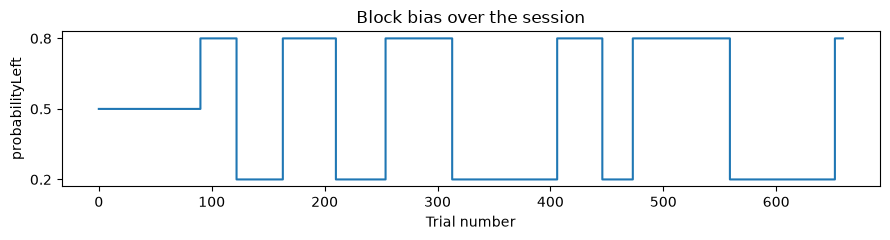

In [5]:
blocks = find_blocks(trials["probabilityLeft"])
print("Number of blocks:", len(blocks))
print("Trials per block bias:", trials["probabilityLeft"].value_counts().sort_index().to_dict())
display(blocks)

fig, ax = plt.subplots(figsize=(9, 2.5))
ax.step(np.arange(len(trials)), trials["probabilityLeft"], where="post")
ax.set_xlabel("Trial number")
ax.set_ylabel("probabilityLeft")
ax.set_yticks([0.2, 0.5, 0.8])
ax.set_title("Block bias over the session")
plt.tight_layout()
plt.show()

## 5. Raw reaction times

Reaction time = `firstMovement_times - stimOn_times`. The red lines are the cleaning limits from `config.yaml`. The plot is cut to -0.5 .. 3 s, so the bar at 3 s holds every trial slower than 3 s. The counts printed above the plot include every trial.

Trials with no reaction time (missing movement or stimulus time): 12
Negative reaction time (moved before the picture): 65
Below 0.08 s (negative ones included): 112
Above 2.0 s: 55
Median (s): 0.178 | Min (s): -0.238 | Max (s): 46.54


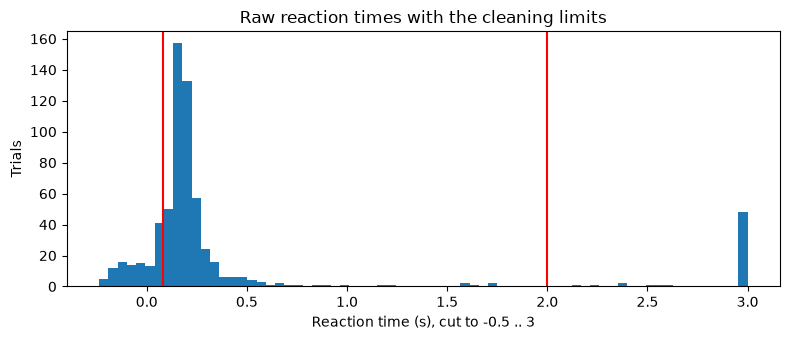

In [6]:
rt = trials["firstMovement_times"] - trials["stimOn_times"]
lo, hi = d["min_reaction_time"], d["max_reaction_time"]
print("Trials with no reaction time (missing movement or stimulus time):", int(rt.isna().sum()))
print("Negative reaction time (moved before the picture):", int((rt < 0).sum()))
print(f"Below {lo} s (negative ones included):", int((rt < lo).sum()))
print(f"Above {hi} s:", int((rt > hi).sum()))
print("Median (s):", round(float(rt.median()), 3), "| Min (s):", round(float(rt.min()), 3), "| Max (s):", round(float(rt.max()), 2))

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(rt.clip(-0.5, 3.0).dropna(), bins=70)
ax.axvline(lo, color="red")
ax.axvline(hi, color="red")
ax.set_xlabel("Reaction time (s), cut to -0.5 .. 3")
ax.set_ylabel("Trials")
ax.set_title("Raw reaction times with the cleaning limits")
plt.tight_layout()
plt.show()

## 6. Neurons per brain region

`load_neurons` loads the good neurons (IBL quality label 1.0) of every probe of the session, gives each its Beryl region, and drops the neurons in `root` and `void`.

Good neurons kept: 429 | Regions: 17
Spikes of these neurons in the whole session: 24114943


,neurons
PO,111
LP,72
IRN,45
VPLpc,43
GRN,34
MV,25
CUL4 5,22
ZI,19
VPM,15
NTS,9


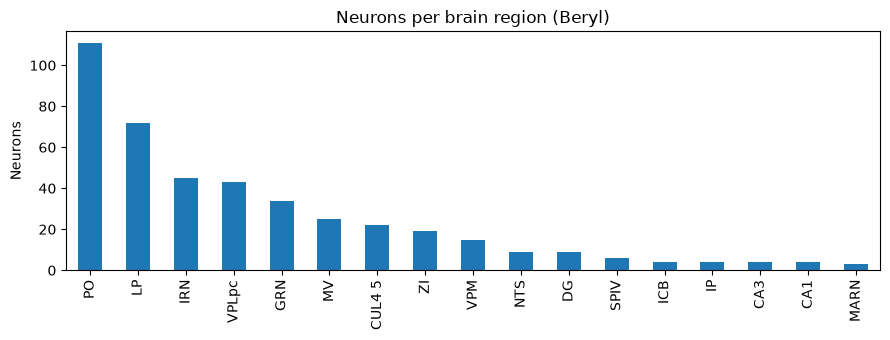

In [7]:
neurons, spikes = load_neurons(one, info["pids"], config)
counts = region_counts(neurons["region"])
print("Good neurons kept:", len(neurons), "| Regions:", counts.size)
print("Spikes of these neurons in the whole session:", len(spikes["times"]))
display(counts.rename("neurons").to_frame())

fig, ax = plt.subplots(figsize=(9, 3.5))
counts.plot.bar(ax=ax)
ax.set_ylabel("Neurons")
ax.set_title("Neurons per brain region (Beryl)")
plt.tight_layout()
plt.show()

## 7. Raster of 20 neurons around the first movement

20 neurons spread evenly over the neuron list (so several regions appear), and the first 30 trials that IBL's mask keeps. Every dot is one spike, placed at its time relative to that trial's first wheel movement. The grey band is our feature window.

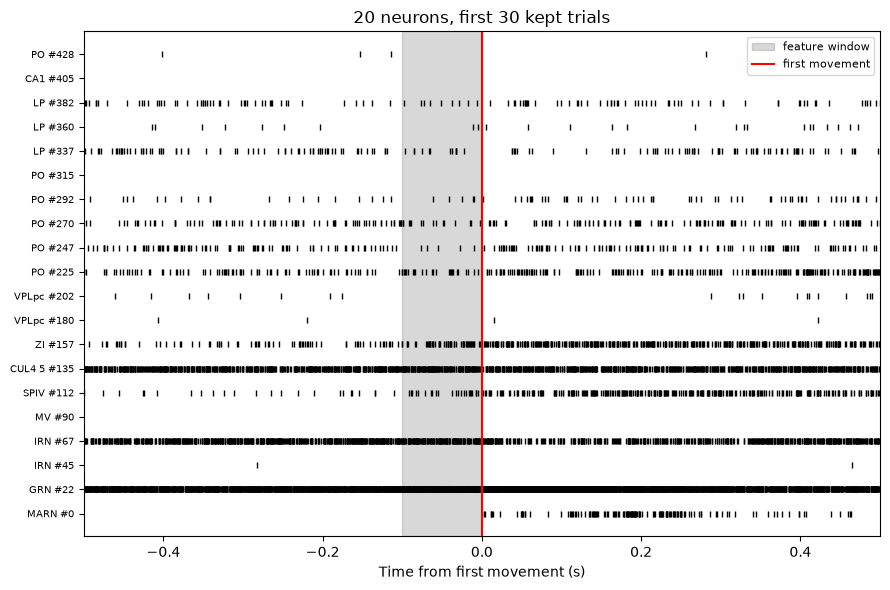

In [8]:
picked = np.linspace(0, len(neurons) - 1, 20).astype(int)
kept = trials.loc[official_mask.to_numpy(), "firstMovement_times"].to_numpy()[:30]
w0, w1 = d["window"]

fig, ax = plt.subplots(figsize=(9, 6))
for row, n in enumerate(picked):
    t = np.sort(spikes["times"][spikes["neuron_index"] == n])
    rel = []
    for m in kept:
        a, b = np.searchsorted(t, [m - 0.5, m + 0.5])
        rel.append(t[a:b] - m)
    rel = np.concatenate(rel) if rel else np.array([])
    ax.plot(rel, np.full(rel.size, row), "|", markersize=5, color="black")
ax.axvspan(w0, w1, color="grey", alpha=0.3, label="feature window")
ax.axvline(0, color="red", label="first movement")
ax.set_yticks(range(len(picked)))
ax.set_yticklabels([f"{neurons.loc[n, 'region']} #{n}" for n in picked], fontsize=7)
ax.set_xlim(-0.5, 0.5)
ax.set_xlabel("Time from first movement (s)")
ax.set_title(f"20 neurons, first {len(kept)} kept trials")
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

## Conclusions - what must the cleaning fix?

- The raw table of this session has 660 trials. IBL's official mask keeps 481 of them, so the cleaning has to remove 179 trials (27%).
- 10 trials have `choice = 0`: the mouse did not answer, so there is no label. They must go.
- 12 trials have no `firstMovement_times` and 2 have no `feedback_times`. Without a movement time there is no feature window, so these must go too (most of them are the same trials as the no-answer ones).
- Reaction time is the biggest problem. 65 trials have a **negative** reaction time: the wheel moved before the picture appeared, so that movement was not a reaction to it. 112 trials are faster than 0.08 s and 55 are slower than 2 s, with the slowest at 46.5 s. These 167 trials are what the reaction-time rule removes.
- The contrast columns are clean: every trial has exactly one side filled. 87 trials have zero contrast; they are kept on purpose, because they are the trials with no picture to read.
- The block bias runs in 12 blocks: a first block of 90 trials at 0.5, then blocks of 0.2 and 0.8 that switch every 8 to 93 trials. So the block bias changes over time, and trials close in time share it. This is one reason the model splits must keep trials in time order.
- The neurons need no extra cleaning: `load_neurons` keeps IBL's good neurons and drops `root` and `void`, leaving 429 neurons in 17 regions (PO 111, LP 72, IRN 45 and smaller ones down to MARN 3).
- The raster shows why the feature window must stop exactly at the movement: some neurons, such as MARN #0, fire almost only **after** the movement starts. If the window crossed the red line, the model could read the movement itself instead of predicting it. Other neurons, such as CA1 #405 and MV #90, barely fire here at all.